EQUIPE:
MARIA EDUARDA RIBEIRO RAMOS e CAIKY DE MORAIS ALVES

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
arquivo = files.upload()

Saving imagem_05.png to imagem_05.png
Saving imagem_04.png to imagem_04.png
Saving imagem_03.png to imagem_03.png
Saving imagem_02.png to imagem_02.png
Saving imagem_01.png to imagem_01.png


# 1. Imagem Original

In [5]:
imagem_01 = cv2.imread('imagem_01.png', cv2.IMREAD_COLOR_RGB)

imagem_02 = cv2.imread('imagem_02.png', cv2.IMREAD_COLOR_RGB)

imagem_03 = cv2.imread('imagem_03.png', cv2.IMREAD_COLOR_RGB)

imagem_04 = cv2.imread('imagem_04.png', cv2.IMREAD_COLOR_RGB)

imagem_05 = cv2.imread('imagem_05.png', cv2.IMREAD_COLOR_RGB)

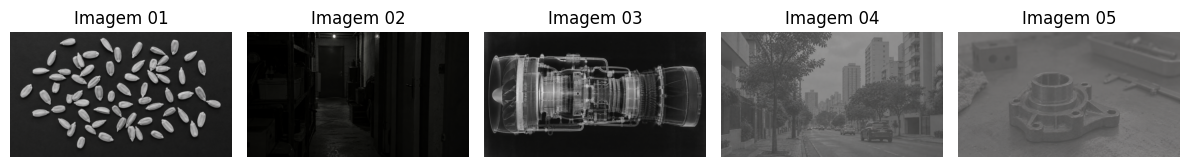

In [6]:
fig, ax = plt.subplots(1,5, figsize=(12,8))

ax[0].imshow(imagem_01)
ax[0].set_title('Imagem 01')
ax[0].axis('off')

ax[1].imshow(imagem_02)
ax[1].set_title('Imagem 02')
ax[1].axis('off')

ax[2].imshow(imagem_03)
ax[2].set_title('Imagem 03')
ax[2].axis('off')

ax[3].imshow(imagem_04)
ax[3].set_title('Imagem 04')
ax[3].axis('off')

ax[4].imshow(imagem_05)
ax[4].set_title('Imagem 05')
ax[4].axis('off')

plt.tight_layout()
plt.show()

# 2. Histograma

In [9]:
def calcHist(img, ax):
    hist_arr = np.zeros(256, dtype=int)

    for px in img:
        hist_arr[px] += 1

    ax.bar(range(256), hist_arr)

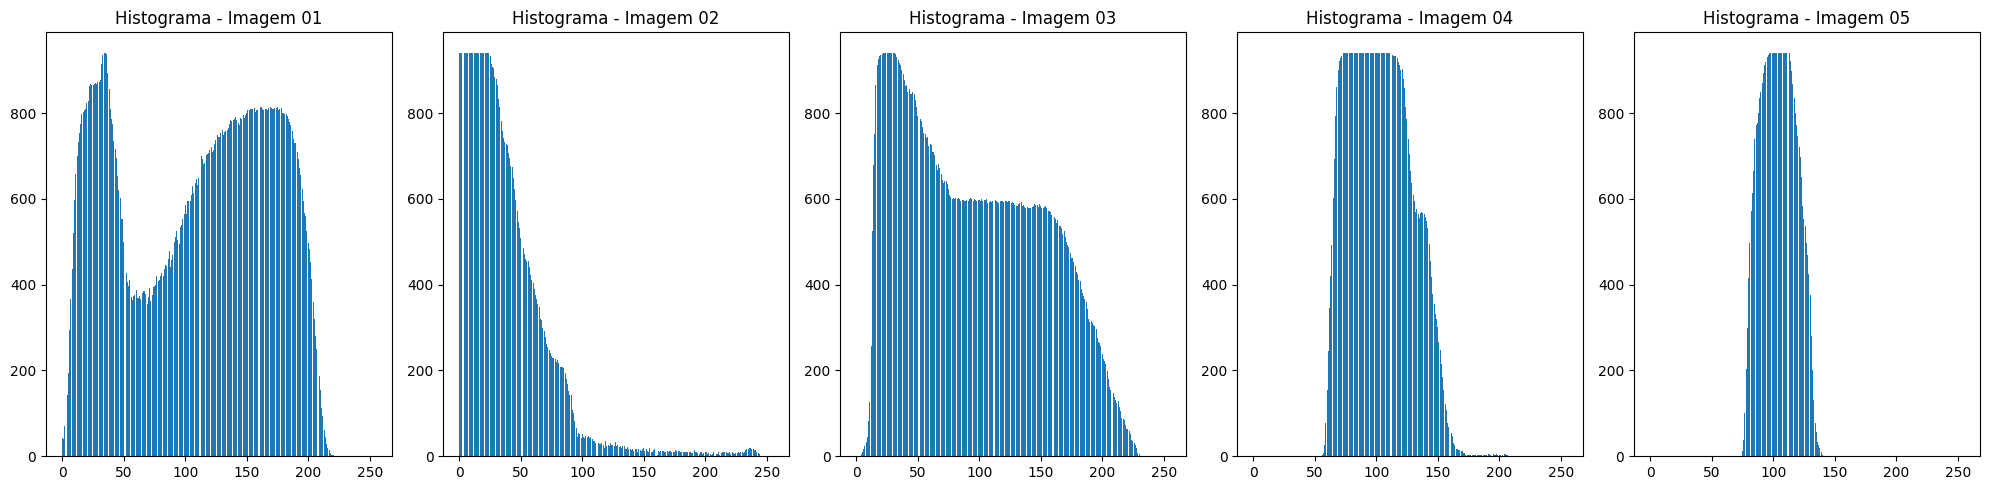

In [14]:
fig, ax = plt.subplots(1, 5, figsize=(20, 5))

calcHist(imagem_01, ax[0])
ax[0].set_title('Histograma - Imagem 01')

calcHist(imagem_02, ax[1])
ax[1].set_title('Histograma - Imagem 02')

calcHist(imagem_03, ax[2])
ax[2].set_title('Histograma - Imagem 03')

calcHist(imagem_04, ax[3])
ax[3].set_title('Histograma - Imagem 04')

calcHist(imagem_05, ax[4])
ax[4].set_title('Histograma - Imagem 05')

plt.tight_layout()
plt.show()

# 3. Diagnóstico

Imagem 01

A imagem apresenta objetos claros sobre fundo escuro, com possibilidade de separar as regiões de interesse. O histograma apresenta concentração de pixels em regiões distintas de intensidade, indicando diferença entre fundo e sementes.



Imagem 02

A imagem possui baixa iluminação, com predominância de pixels escuros. O histograma está concentrado nos níveis baixos de intensidade, indicando que poucos pixels possuem valores elevados de brilho.

Imagem 03

A imagem apresenta estruturas internas claras sobre um fundo escuro. Apesar do contraste existente, alguns detalhes podem ser realçados pela inversão dos níveis de intensidade.


Imagem 04

A imagem apresenta baixo contraste, com predominância de tons intermediários. O histograma está concentrado em uma faixa limitada de intensidades, indicando que a imagem não utiliza toda a faixa de níveis de cinza.


Imagem 05

A imagem apresenta baixo contraste, com pouca diferenciação entre a peça e o fundo. O histograma demonstra concentração dos pixels em uma faixa reduzida de intensidade, indicando pouca variação dos níveis de cinza.



# 4. Técnica/Parâmetros

Imagem 01: Limiarização

Imagem 02: Correção Gamma + Equalização de Histograma

Imagem 03: Negativo Digital

Imagem 04: Expansão de Contraste + Equalização de Histograma

Imagem 05: Expansão de Contraste + Equalização de Histograma

# 5. Resultado e Histograma

In [15]:
def limiarizacao_pixel_a_pixel(imagem, limiar, tipo="superior"):

    resultado = np.zeros_like(imagem)

    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):

            if tipo == "superior":
                if imagem[i, j] >= limiar:
                    resultado[i, j] = 255

            elif tipo == "inferior":
                if imagem[i, j] <= limiar:
                    resultado[i, j] = 255

    return resultado

In [21]:
imagem_01_gray = cv2.cvtColor(imagem_01, cv2.COLOR_BGR2GRAY)
imagem_01_limiarizacao = limiarizacao_pixel_a_pixel(imagem_01_gray, 120)

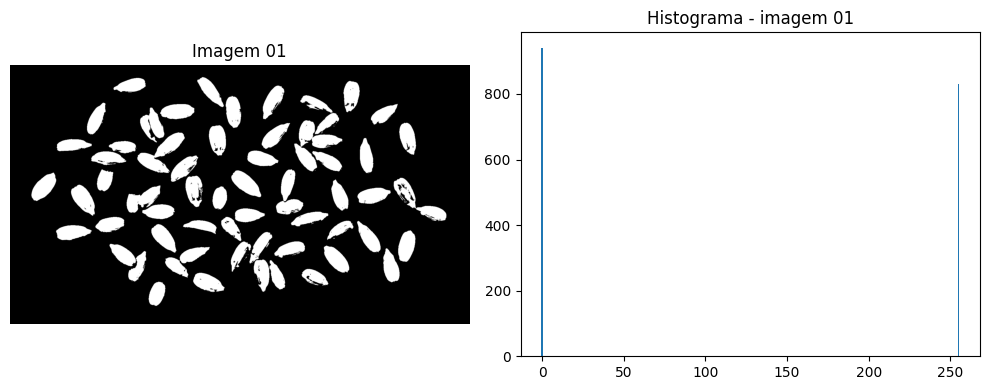

In [29]:
fig, ax = plt.subplots(1,2, figsize=(10,4))

ax[0].imshow(imagem_01_limiarizacao, cmap='gray')
ax[0].set_title('Imagem 01')
ax[0].axis('off')

calcHist(imagem_01_limiarizacao, ax[1])
ax[1].set_title('Histograma - imagem 01')

plt.tight_layout()
plt.show()



---



In [30]:
def correcao_gamma_pixel_a_pixel(imagem, gamma):

    if gamma <= 0:
        raise ValueError("O valor de gamma deve ser maior que zero.")

    resultado = np.zeros_like(imagem)

    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):
            r = imagem[i, j] / 255.0
            resultado[i, j] = 255 * (r ** gamma)

    return resultado.astype(np.uint8)

In [33]:
def equalizacao_histograma_manual(imagem):

    histograma = np.zeros(256, dtype=int)

    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):
            nivel = imagem[i, j]
            histograma[nivel] += 1

    cdf = np.cumsum(histograma)

    cdf_normalizada = 255 * cdf / cdf[-1]

    resultado = np.zeros_like(imagem)

    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):
            resultado[i, j] = cdf_normalizada[imagem[i, j]]

    return resultado.astype(np.uint8)

In [34]:
imagem_02_gray = cv2.cvtColor(imagem_02, cv2.COLOR_BGR2GRAY)
imagem_02_gamma = correcao_gamma_pixel_a_pixel(imagem_02_gray, 0.5)
imagem_02_gamma_equalizacao = equalizacao_histograma_manual(imagem_02_gamma)

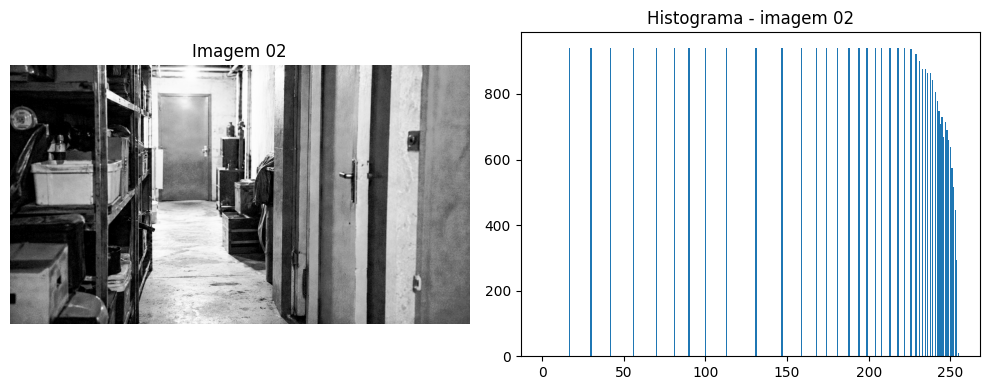

In [35]:
fig, ax = plt.subplots(1,2, figsize=(10,4))

ax[0].imshow(imagem_02_gamma_equalizacao, cmap='gray')
ax[0].set_title('Imagem 02')
ax[0].axis('off')

calcHist(imagem_02_gamma_equalizacao, ax[1])
ax[1].set_title('Histograma - Imagem 02')

plt.tight_layout()
plt.show()



---



In [37]:
def negativo_pixel_a_pixel(imagem):

    resultado = imagem.copy()

    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):
            resultado[i, j] = 255 - imagem[i, j]

    return resultado

In [38]:
imagem_03_gray = cv2.cvtColor(imagem_03, cv2.COLOR_BGR2GRAY)
imagem_03_negativo = negativo_pixel_a_pixel(imagem_03_gray)

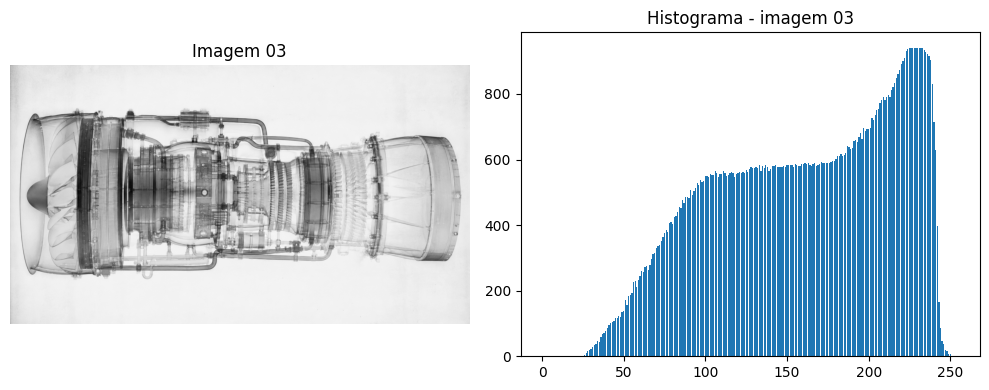

In [39]:
fig, ax = plt.subplots(1,2, figsize=(10,4))

ax[0].imshow(imagem_03_negativo, cmap='gray')
ax[0].set_title('Imagem 03')
ax[0].axis('off')

calcHist(imagem_03_negativo, ax[1])
ax[1].set_title('Histograma - Imagem 03')

plt.tight_layout()
plt.show()



---



In [48]:
def expansao_contraste_pixel_a_pixel(imagem):

    L = imagem.min()
    H = imagem.max()

    if H == L:
        return imagem.copy()

    resultado = np.zeros_like(imagem, dtype=np.float32)

    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):

            pixel = float(imagem[i,j])

            resultado[i,j] = (
                (pixel - L) * 255 / (H - L)
            )

    return resultado.astype(np.uint8)

In [49]:
imagem_04_gray = cv2.cvtColor(imagem_04, cv2.COLOR_BGR2GRAY)
imagem_04_contraste = expansao_contraste_pixel_a_pixel(imagem_04_gray)
imagem_04_contraste_equalizacao = equalizacao_histograma_manual(imagem_04_contraste)

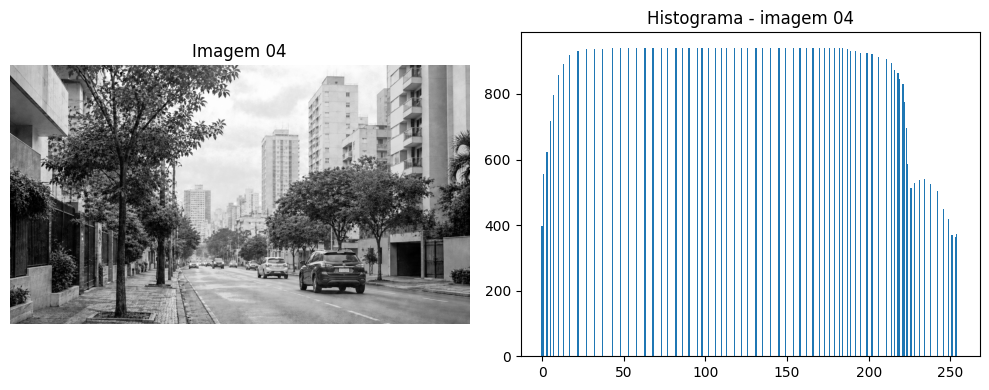

In [50]:
fig, ax = plt.subplots(1,2, figsize=(10,4))

ax[0].imshow(imagem_04_contraste_equalizacao, cmap='gray')
ax[0].set_title('Imagem 04')
ax[0].axis('off')

calcHist(imagem_04_contraste_equalizacao, ax[1])
ax[1].set_title('Histograma - Imagem 04')

plt.tight_layout()
plt.show()



---



In [51]:
imagem_05_gray = cv2.cvtColor(imagem_05, cv2.COLOR_BGR2GRAY)
imagem_05_contraste = expansao_contraste_pixel_a_pixel(imagem_05_gray)
imagem_05_contraste_equalizacao = equalizacao_histograma_manual(imagem_05_contraste)

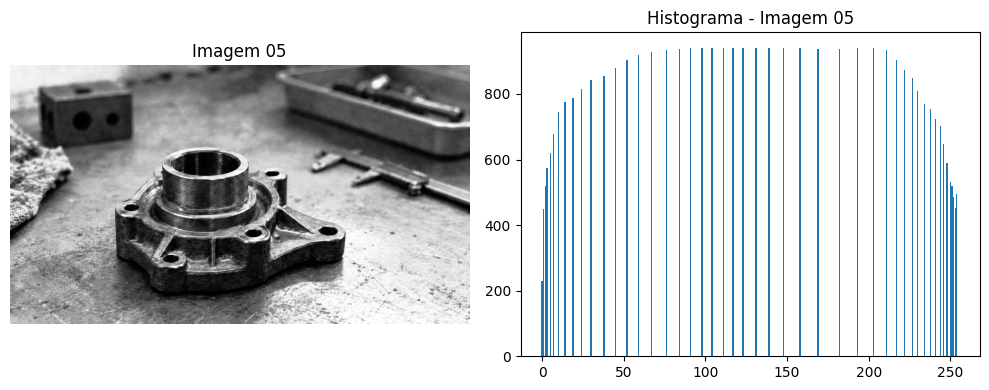

In [53]:
fig, ax = plt.subplots(1,2, figsize=(10,4))

ax[0].imshow(imagem_05_contraste_equalizacao, cmap='gray')
ax[0].set_title('Imagem 05')
ax[0].axis('off')

calcHist(imagem_05_contraste_equalizacao, ax[1])
ax[1].set_title('Histograma - Imagem 05')

plt.tight_layout()
plt.show()

# 6. Final (2x2)

Text(0.5, 1.0, 'Final - Histograma')

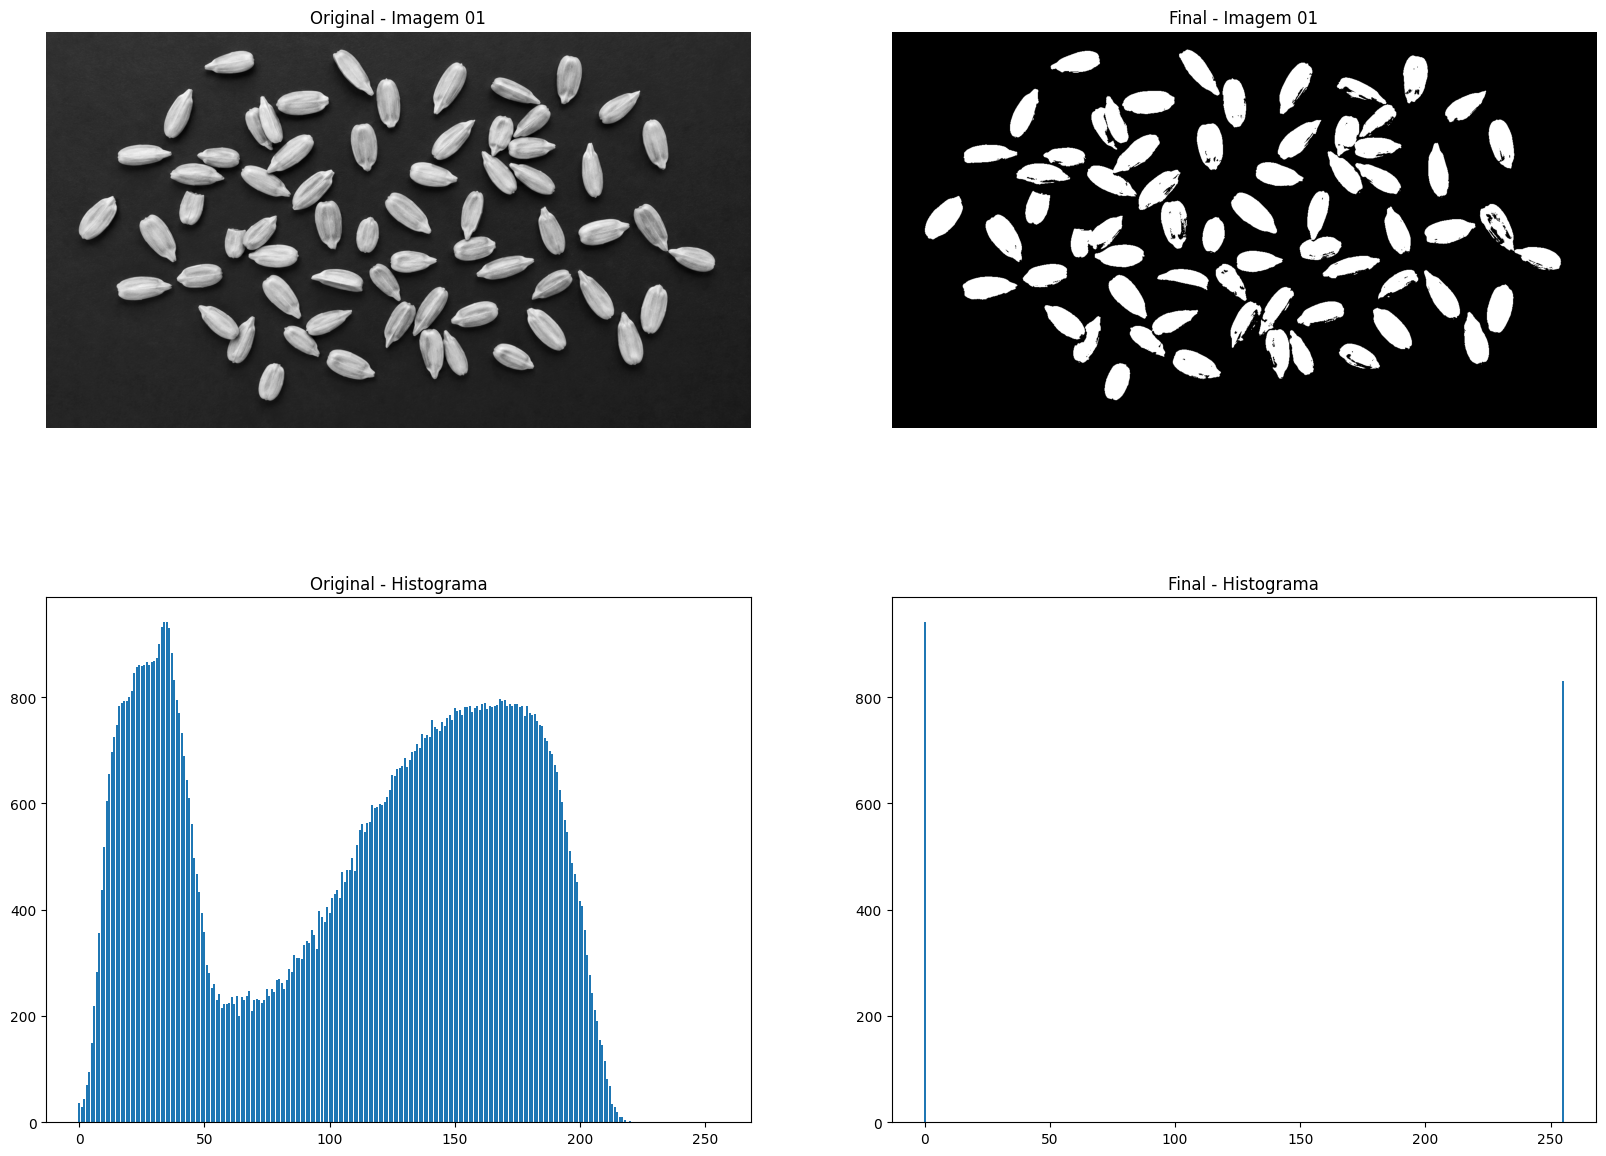

In [55]:
fig, ax = plt.subplots(2,2, figsize=(20,15))

ax[0,0].imshow(imagem_01_gray, cmap='gray')
ax[0,0].set_title('Original - Imagem 01')
ax[0,0].axis('off')

calcHist(imagem_01_gray, ax[1,0])
ax[1,0].set_title('Original - Histograma')

ax[0,1].imshow(imagem_01_limiarizacao, cmap='gray')
ax[0,1].set_title('Final - Imagem 01')
ax[0,1].axis('off')

calcHist(imagem_01_limiarizacao, ax[1,1])
ax[1,1].set_title('Final - Histograma')

A imagem passou por limiarização, transformando os níveis de cinza em uma imagem binária. O histograma final apresenta dois picos principais, próximos de 0 e 255, indicando a separação entre o fundo escuro e as sementes claras. O processamento aumentou a capacidade de identificar os objetos de interesse.



---



Text(0.5, 1.0, 'Final - Histograma')

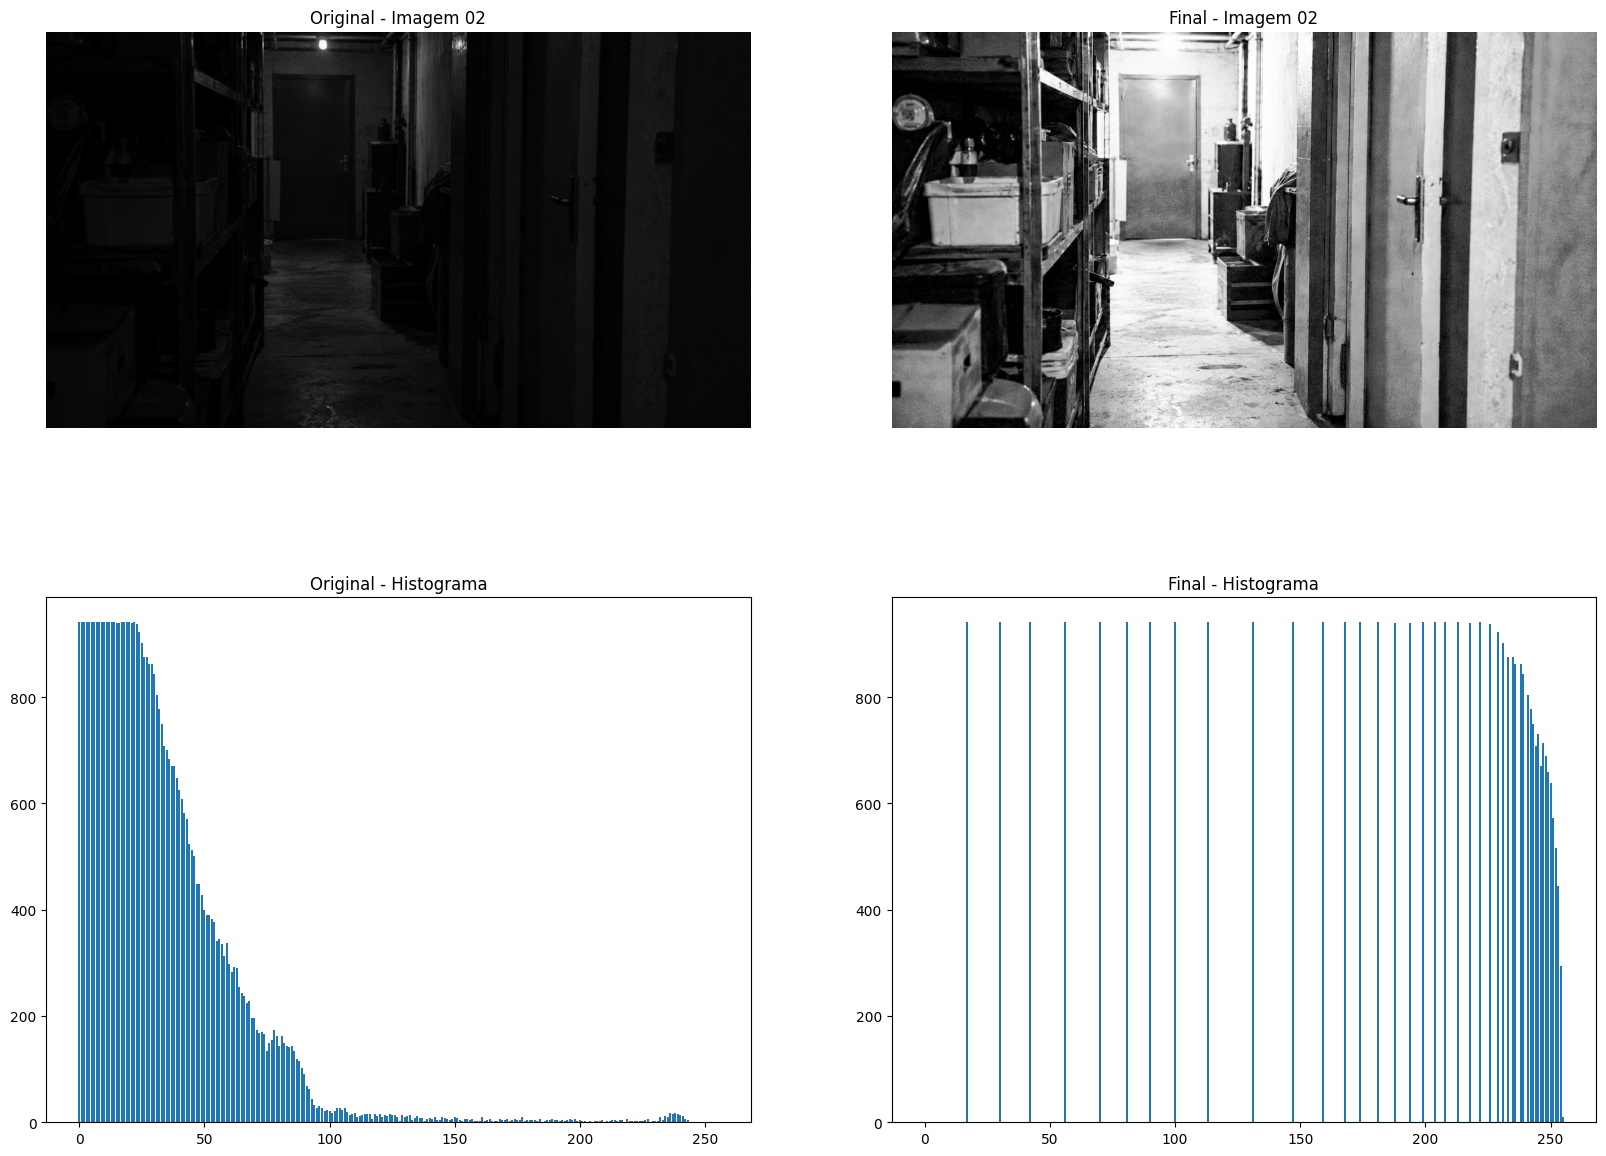

In [56]:
fig, ax = plt.subplots(2,2, figsize=(20,15))

ax[0,0].imshow(imagem_02_gray, cmap='gray')
ax[0,0].set_title('Original - Imagem 02')
ax[0,0].axis('off')

calcHist(imagem_02_gray, ax[1,0])
ax[1,0].set_title('Original - Histograma')

ax[0,1].imshow(imagem_02_gamma_equalizacao, cmap='gray')
ax[0,1].set_title('Final - Imagem 02')
ax[0,1].axis('off')

calcHist(imagem_02_gamma_equalizacao, ax[1,1])
ax[1,1].set_title('Final - Histograma')

A correção Gamma aumentou a luminosidade da imagem, permitindo visualizar detalhes que estavam ocultos nas regiões escuras. O histograma final apresenta uma redistribuição dos pixels para valores de intensidade mais elevados, demonstrando o aumento do brilho e da informação visual.



---



Text(0.5, 1.0, 'Final - Histograma')

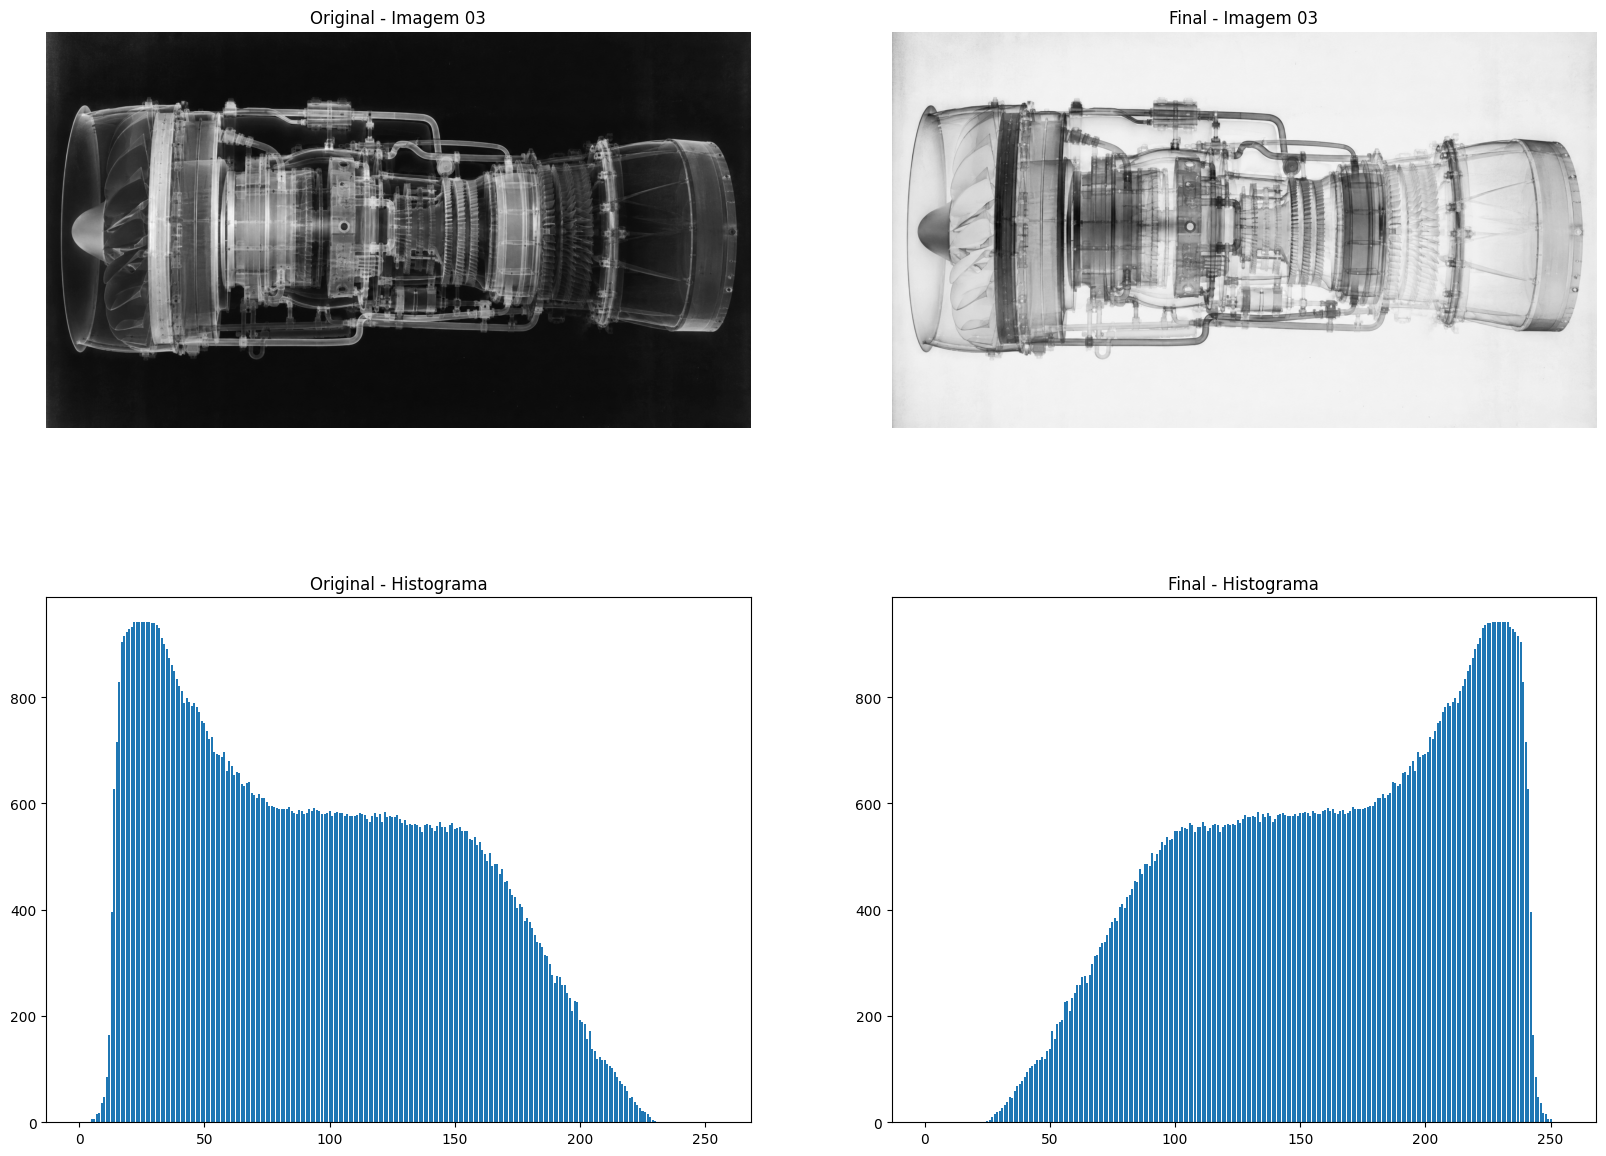

In [57]:
fig, ax = plt.subplots(2,2, figsize=(20,15))

ax[0,0].imshow(imagem_03_gray, cmap='gray')
ax[0,0].set_title('Original - Imagem 03')
ax[0,0].axis('off')

calcHist(imagem_03_gray, ax[1,0])
ax[1,0].set_title('Original - Histograma')

ax[0,1].imshow(imagem_03_negativo, cmap='gray')
ax[0,1].set_title('Final - Imagem 03')
ax[0,1].axis('off')

calcHist(imagem_03_negativo, ax[1,1])
ax[1,1].set_title('Final - Histograma')

O negativo digital foi aplicado, invertendo os níveis de intensidade da imagem. O histograma final apresenta uma distribuição invertida em relação ao original, deslocando os pixels claros para regiões mais escuras e vice-versa, destacando estruturas internas do objeto.



---



Text(0.5, 1.0, 'Final - Histograma')

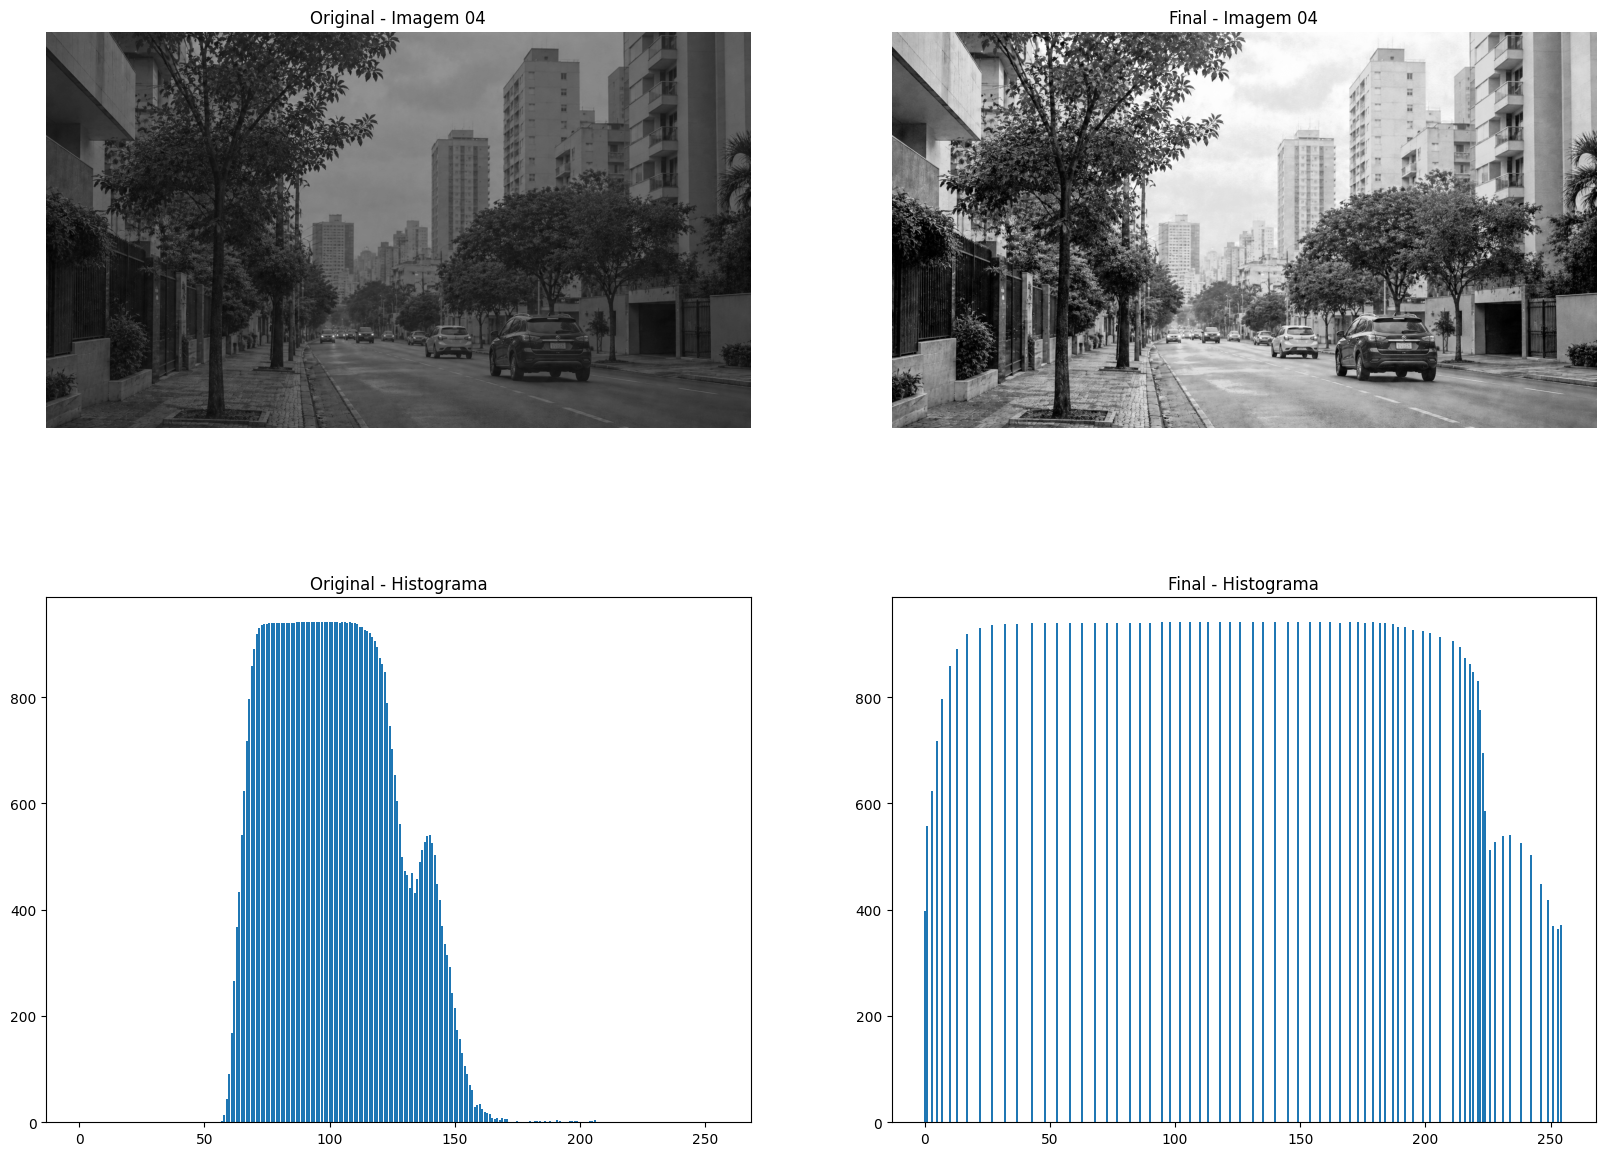

In [58]:
fig, ax = plt.subplots(2,2, figsize=(20,15))

ax[0,0].imshow(imagem_04_gray, cmap='gray')
ax[0,0].set_title('Original - Imagem 04')
ax[0,0].axis('off')

calcHist(imagem_04_gray, ax[1,0])
ax[1,0].set_title('Original - Histograma')

ax[0,1].imshow(imagem_04_contraste_equalizacao, cmap='gray')
ax[0,1].set_title('Final - Imagem 04')
ax[0,1].axis('off')

calcHist(imagem_04_contraste_equalizacao, ax[1,1])
ax[1,1].set_title('Final - Histograma')

A expansão de contraste e a equalização do histograma ampliaram a faixa de intensidades utilizadas pela imagem. O histograma final apresenta uma distribuição mais uniforme dos níveis de cinza, resultando em maior contraste entre regiões claras e escuras e melhor visualização dos detalhes da cena.



---



Text(0.5, 1.0, 'Final - Histograma')

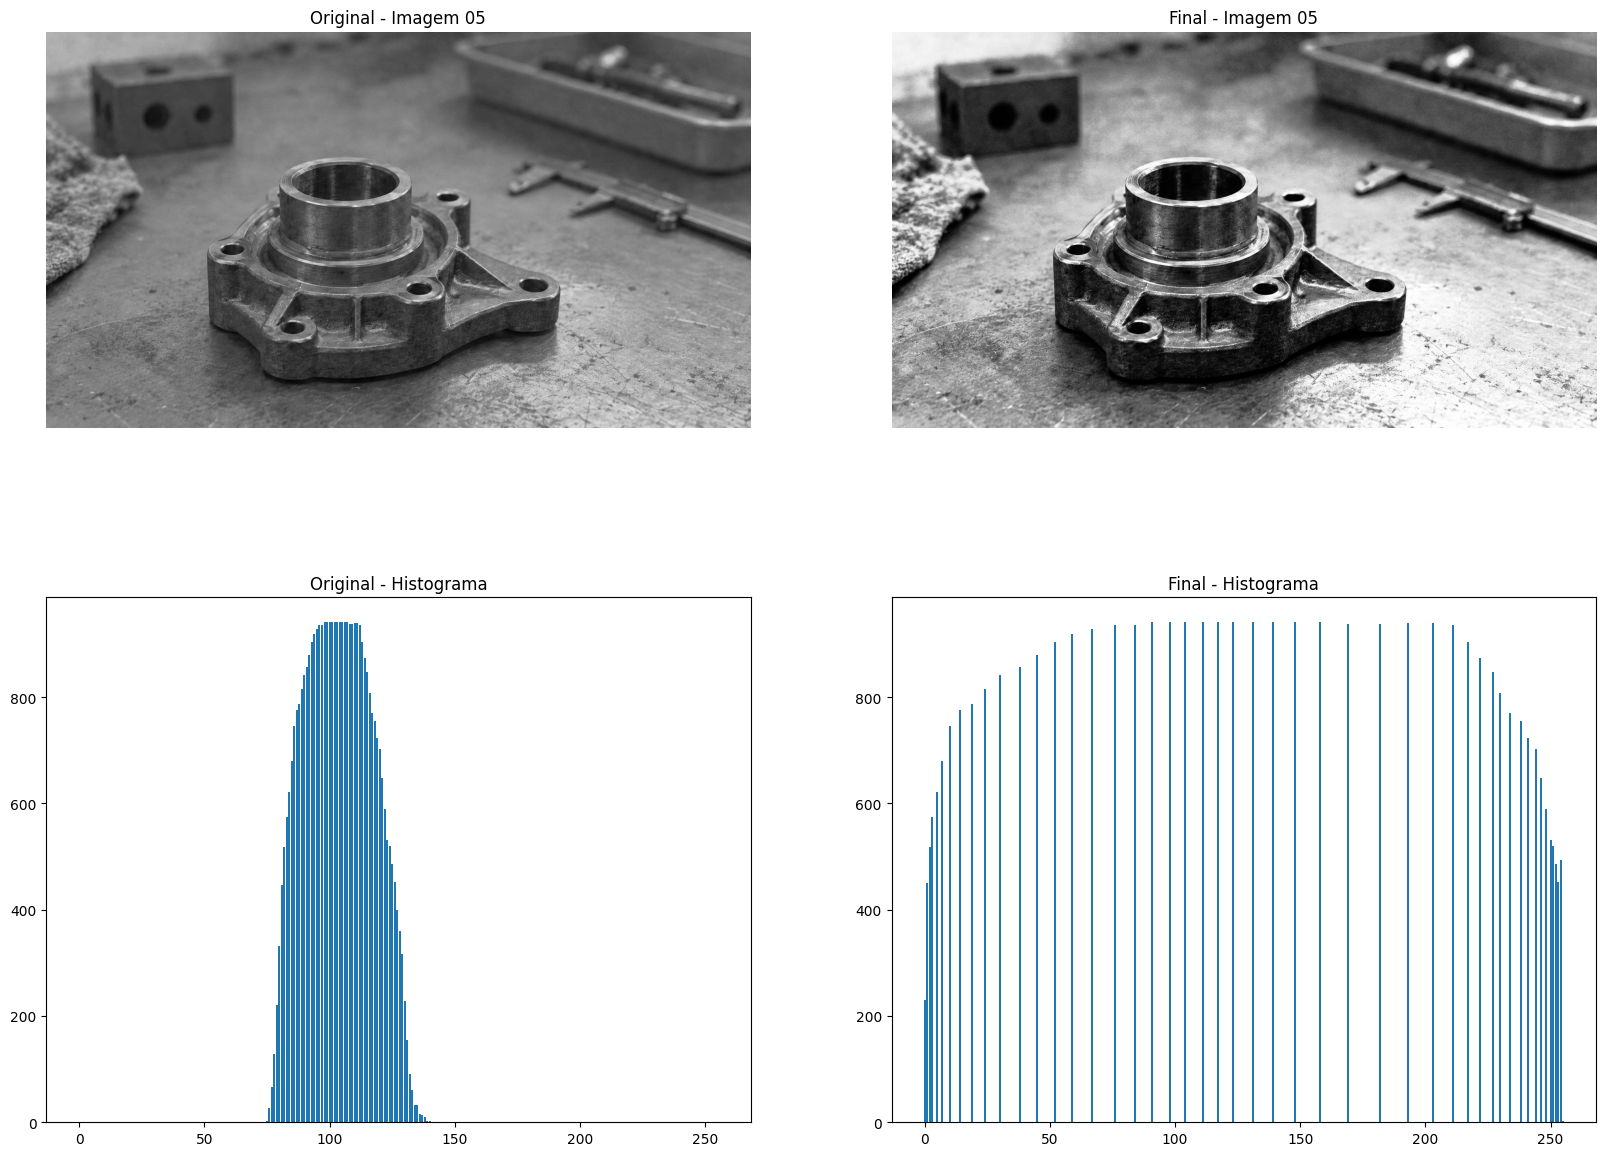

In [59]:
fig, ax = plt.subplots(2,2, figsize=(20,15))

ax[0,0].imshow(imagem_05_gray, cmap='gray')
ax[0,0].set_title('Original - Imagem 05')
ax[0,0].axis('off')

calcHist(imagem_05_gray, ax[1,0])
ax[1,0].set_title('Original - Histograma')

ax[0,1].imshow(imagem_05_contraste_equalizacao, cmap='gray')
ax[0,1].set_title('Final - Imagem 05')
ax[0,1].axis('off')

calcHist(imagem_05_contraste_equalizacao, ax[1,1])
ax[1,1].set_title('Final - Histograma')

A expansão de contraste combinada com a equalização de histograma aumentou a diferença entre os tons presentes na imagem. O histograma final apresenta maior distribuição dos níveis de cinza em comparação ao original, melhorando a definição da peça metálica e destacando seus detalhes estruturais.

# 7. Justificativa

Imagem 01

A limiarização é adequada porque permite definir um valor de corte (limiar T) para separar pixels com diferentes intensidades. Dessa forma, é possível destacar as sementes do fundo, criando uma separação entre regiões claras e escuras da imagem.

Imagem 02

A correção Gamma foi escolhida porque permite ajustar o brilho percebido da imagem, sendo indicada para clarear regiões escuras quando utilizado γ menor que 1. A equalização do histograma complementa o processo ao redistribuir as intensidades dos pixels ao longo da faixa disponível.

Imagem 03

O negativo digital foi escolhido porque realiza a inversão dos níveis de cinza da imagem. Segundo o slide, essa operação permite transformar valores escuros em claros e valores claros em escuros, possibilitando destacar detalhes presentes na imagem original.


Imagem 04

A expansão de contraste foi escolhida para ampliar a faixa de valores de intensidade, aumentando a diferença entre regiões claras e escuras. A equalização foi aplicada para redistribuir os níveis de cinza e melhorar a utilização da faixa de intensidades da imagem.


Imagem 05

A expansão de contraste foi escolhida para ampliar a faixa de níveis de cinza da imagem, aumentando a diferença entre as regiões claras e escuras e destacando os detalhes da peça. A equalização de histograma foi aplicada para redistribuir as intensidades dos pixels ao longo da faixa disponível, melhorando a distribuição dos níveis de cinza e contribuindo para uma melhor visualização dos detalhes.

# 8. Quantização

In [65]:
img_original = imagem_05_contraste_equalizacao

img_16_niveis = np.round(img_original / 255 * 15) / 15 * 255

img_8_niveis = np.round(img_original / 255 * 7) / 7 * 255

img_4_niveis = np.round(img_original / 255 * 3) / 3 * 255

img_16_niveis = img_16_niveis.astype(np.uint8)
img_8_niveis = img_8_niveis.astype(np.uint8)
img_4_niveis = img_4_niveis.astype(np.uint8)

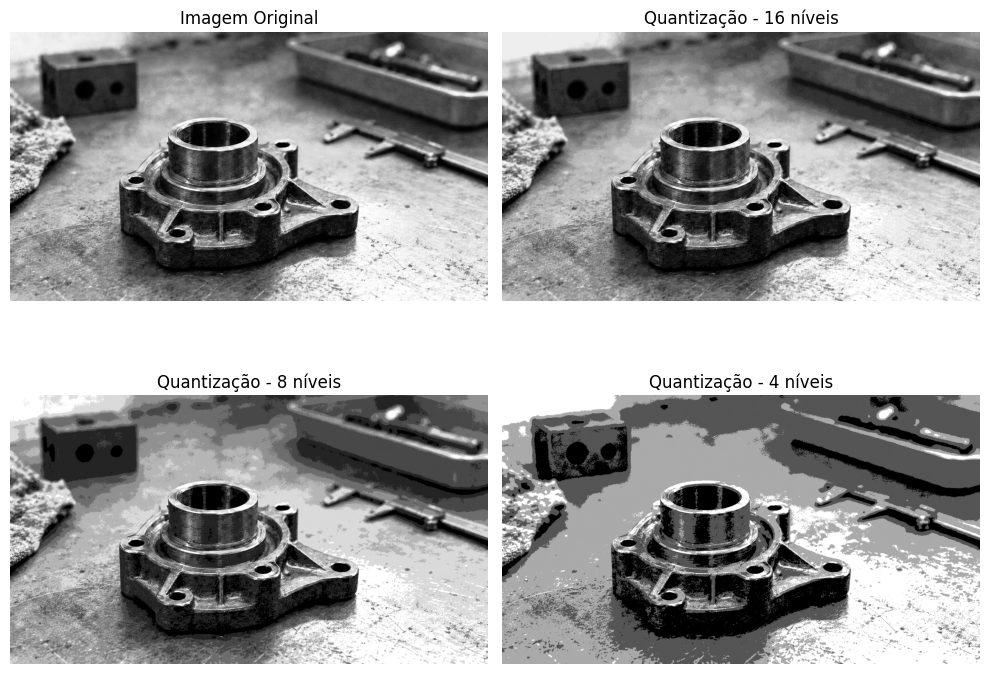

In [66]:
plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
plt.imshow(img_original, cmap="gray")
plt.title("Imagem Original")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(img_16_niveis, cmap="gray")
plt.title("Quantização - 16 níveis")
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(img_8_niveis, cmap="gray")
plt.title("Quantização - 8 níveis")
plt.axis("off")

plt.subplot(2,2,4)
plt.imshow(img_4_niveis, cmap="gray")
plt.title("Quantização - 4 níveis")
plt.axis("off")

plt.tight_layout()
plt.show()

A quantização da Imagem 05 demonstra a redução progressiva dos níveis de cinza utilizados para representar a imagem. Com 16 níveis de cinza, a diferença visual em relação à imagem original é pequena, mantendo boa parte dos detalhes. Com 8 níveis, ocorre uma perda moderada de informações, principalmente nas regiões com transições suaves de intensidade. Já com 4 níveis de cinza, a perda visual torna-se mais perceptível, devido ao agrupamento dos tons e à redução dos detalhes presentes na imagem.